# Solving systems of linear equations

Goes with the lecture note of the same name. Run the cells from top to bottom, then change the numbers.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. The example from the note

$$0.44\,x - 0.24\,y = 10, \qquad -0.16\,x + 0.36\,y = 1$$

In [2]:
A = np.array([[0.44, -0.24],
              [-0.16, 0.36]])
b = np.array([10.0, 1.0])

print("determinant:", np.linalg.det(A))      # not zero, so there is exactly one solution
print("inverse:\n", np.linalg.inv(A))
print("inverse times b:", np.linalg.inv(A) @ b)
print("solve:", np.linalg.solve(A, b))       # preferred: faster and more accurate

determinant: 0.12000000000000001
inverse:
 [[3.         2.        ]
 [1.33333333 3.66666667]]
inverse times b: [32. 17.]
solve: [32. 17.]


## 2. The picture: each equation is a line, the solution is where they cross

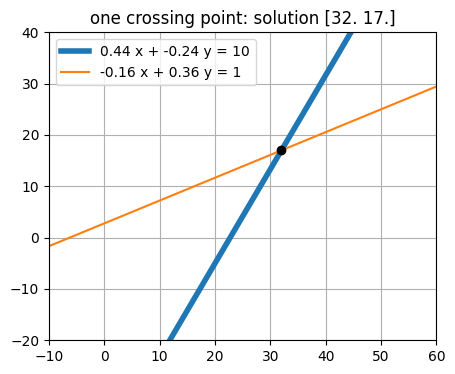

In [3]:
def plot_lines(A, b, title):
    "Draws the two lines a*x + c*y = r, one for each row of A."
    t = np.linspace(-10, 60, 2)
    plt.figure(figsize=(5, 4))
    for (a, c), r, width in zip(A, b, [4, 1.5]):
        plt.plot(t, (r - a * t) / c, linewidth=width, label=f"{a:g} x + {c:g} y = {r:g}")
    if abs(np.linalg.det(A)) > 1e-12:
        x = np.linalg.solve(A, b)
        plt.plot(*x, "ko"); title += f": solution {np.round(x, 3)}"
    plt.xlim(-10, 60); plt.ylim(-20, 40); plt.grid(True); plt.legend(); plt.title(title); plt.show()

plot_lines(A, b, "one crossing point")

## 3. When there is no inverse

Here the determinant is 0. Look at the two lines.

determinant: 0.0


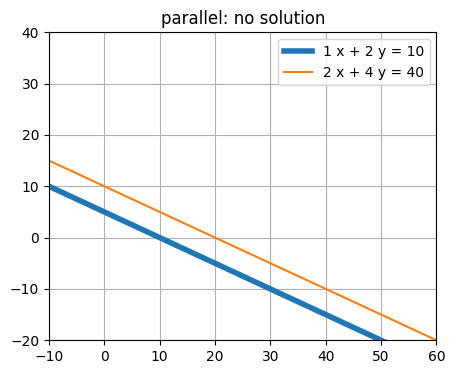

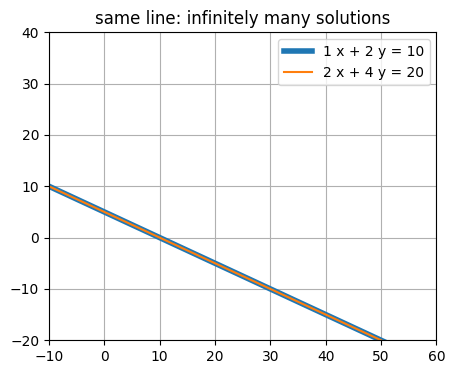

numpy says: Singular matrix


In [4]:
P = np.array([[1.0, 2.0],
              [2.0, 4.0]])
print("determinant:", np.linalg.det(P))
plot_lines(P, [10, 40], "parallel: no solution")
plot_lines(P, [10, 20], "same line: infinitely many solutions")

try:
    np.linalg.solve(P, [10, 40])
except np.linalg.LinAlgError as error:
    print("numpy says:", error)

## 4. Larger systems: the same lines of code

In [5]:
rng = np.random.default_rng(0)
n = 1000
A_big = rng.normal(size=(n, n))
b_big = rng.normal(size=n)
x_big = np.linalg.solve(A_big, b_big)
with np.errstate(all="ignore"):               # some Macs raise false warnings here
    error = np.abs(A_big @ x_big - b_big).max()
print(n, "unknowns. Largest error in A x - b:", error)

1000 unknowns. Largest error in A x - b: 1.8106160017475337e-12


## 5. Sensitivity

Change $\mathbf{b}$ a little. How much does the solution change?

In [6]:
Q = np.array([[1, 1],
              [1, 1.001]])
for b2 in [2, 2.001]:
    print("b =", [2, b2], "  x =", np.linalg.solve(Q, [2, b2]))
print("determinant:", np.linalg.det(Q), "  condition number:", np.linalg.cond(Q))

b = [2, 2]   x = [2. 0.]
b = [2, 2.001]   x = [1. 1.]
determinant: 0.00099999999999989   condition number: 4002.0007501252458


## Exercise 1

Do part (a) of Exercise 1 by hand first. Then type in your $A$ and $\mathbf{b}$ and compare.

In [7]:
# A = np.array([[..., ...],
#               [..., ...]])
# b = np.array([..., ...])
# print(np.linalg.det(A), np.linalg.inv(A), np.linalg.solve(A, b))

## Exercise 2: the rotation matrix

Solve $R(\theta)\,\mathbf{x} = \mathbf{b}$ by hand first. Then run the cell. What do you see, and what does it have to
do with $\theta$? Change `degrees` and run it again.

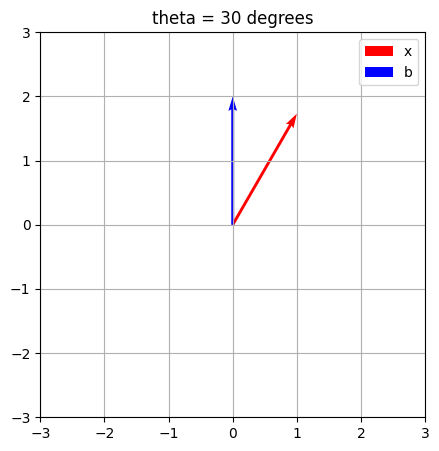

x = [1.         1.73205081]
lengths: 2.0 2.0
determinant: 1.0


In [8]:
degrees = 30
theta = np.radians(degrees)
R = np.array([[np.cos(theta), -np.sin(theta)],
              [np.sin(theta),  np.cos(theta)]])
b = np.array([0.0, 2.0])
x = np.linalg.solve(R, b)

fig, ax = plt.subplots(figsize=(5, 5))
for v, c, name in [(x, "red", "x"), (b, "blue", "b")]:
    ax.quiver(0, 0, *v, angles="xy", scale_units="xy", scale=1, color=c, label=name)
ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal"); ax.grid(True); ax.legend()
ax.set_title(f"theta = {degrees} degrees"); plt.show()

print("x =", x)
print("lengths:", np.linalg.norm(x), np.linalg.norm(b))
print("determinant:", np.linalg.det(R))